# Practical Session 4 - Overfitting, data leakage and generalization
Goal: predict `final_cgpa` (regression). Metrics: RMSE and R². Baseline = predict the training mean.

In [22]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")

from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, PolynomialFeatures, OneHotEncoder, TargetEncoder
from sklearn.model_selection import train_test_split, TimeSeriesSplit, cross_val_score
from sklearn.tree import DecisionTreeRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_squared_error, r2_score

np.random.seed(42)

def rmse(y_true, y_pred):
    return np.sqrt(mean_squared_error(y_true, y_pred))

# Part A - Data inspection

### A.1 Load the data

In [23]:
import os
import pandas as pd

df = pd.read_csv("hybrid_student_performance_1200 - hybrid_student_performance_1200.csv")

df["timestamp"] = pd.to_datetime(df["timestamp"])

print(df.shape)
print(df.dtypes.value_counts())

df.describe()

(1200, 36)
str               30
float64            4
datetime64[us]     1
int64              1
Name: count, dtype: int64


,timestamp,age,daily_productivity,energy_level,stress_level,routine_rating
count,1200,1200.000000,1166.000000,1172.000000,1165.000000,1159.000000
mean,2026-03-30 07:20:15.285000,20.807500,2.686964,3.227816,3.151931,2.105263
min,2026-03-15 01:07:00,17.000000,1.000000,1.000000,1.000000,1.000000
25%,2026-03-22 10:58:30,19.000000,2.000000,2.000000,2.000000,1.000000
50%,2026-03-30 09:05:00,21.000000,3.000000,3.000000,3.000000,2.000000
75%,2026-04-06 23:02:00,22.000000,3.000000,4.000000,4.000000,3.000000
max,2026-04-14 22:27:00,26.000000,5.000000,5.000000,5.000000,3.000000
std,NaN,2.186953,1.178761,1.145359,1.189194,0.788057


In [24]:
missing = (df.isna().mean() * 100).round(2)
print(missing[missing > 0].sort_values(ascending=False))

events_participation      4.83
sleep_hours               4.58
external_resources        3.75
focus_duration            3.58
routine_rating            3.42
programming_foundation    3.42
online_courses            3.00
stress_level              2.92
daily_productivity        2.83
revision_frequency        2.83
screen_time_non_study     2.67
external_pressure         2.42
energy_level              2.33
dtype: float64


### A.2 Duplicates

In [25]:
print("all columns:", df.duplicated().sum())
print("without student_id:", df.drop(columns="student_id").duplicated().sum())
print("without timestamp:", df.drop(columns="timestamp").duplicated().sum())
print("without both:", df.drop(columns=["student_id", "timestamp"]).duplicated().sum())

all columns: 0
without student_id: 0
without timestamp: 0
without both: 0


There are no duplicates in the file, so I will create some in Part B.2.

### A.3 Build the target and the features

age                   -0.024
sleep_hours           -0.010
stress_level           0.019
submission_day         0.020
revision_frequency     0.071
assignments_on_time    0.076
tasks_on_time          0.097
career_goal_clarity    0.121
daily_productivity     0.132
study_hours            0.297
study_consistency      0.322
attendance_rate        0.365
effort_index           0.377
dtype: float64


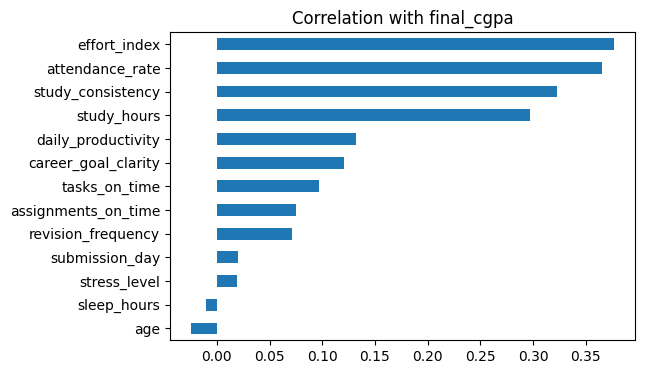

In [26]:
cgpa_map = {"5.0 – 6.9": 5.95, "7.0 – 8.4": 7.70, "8.5 – 9.4": 8.95, "9.5 – 10.0": 9.75}
study_map = {"Less than 1 hour": 0.5, "1–2 hours": 1.5, "More than 2 hours": 2.5}
sleep_map = {"4–5 hours": 4.5, "6–7 hours": 6.5, "More than 8 hours": 8.5}
att_map = {"Less than 50%": 40, "50% – 65%": 57.5, "66% – 75%": 70.5, "76% – 85%": 80.5, "Above 85%": 92.5}
cons_map = {"Rarely": 0, "Sometimes": 1, "Mostly consistent": 2}
ontime_map = {"Rarely": 0, "Sometimes": 1, "Often": 2, "Always": 3}
rev_map = {"Never": 0, "Rarely": 1, "Few times a week": 2, "Daily": 3}
goal_map = {"Not clear": 0, "Somewhat clear": 1, "Very clear": 2}

T0 = df["timestamp"].min()   # first submission

def build(raw):
    d = pd.DataFrame(index=raw.index)
    d["final_cgpa"] = raw["cgpa_category"].map(cgpa_map)
    d["study_hours"] = raw["study_hours_daily"].map(study_map)
    d["sleep_hours"] = raw["sleep_hours"].map(sleep_map)
    d["attendance_rate"] = raw["attendance_percentage"].map(att_map)
    d["study_consistency"] = raw["study_consistency"].map(cons_map)
    d["tasks_on_time"] = raw["tasks_on_time"].map(ontime_map)
    d["assignments_on_time"] = raw["assignments_on_time"].map(ontime_map)
    d["revision_frequency"] = raw["revision_frequency"].map(rev_map)
    d["career_goal_clarity"] = raw["career_goal_clarity"].map(goal_map)
    d["daily_productivity"] = raw["daily_productivity"]
    d["stress_level"] = raw["stress_level"]
    d["age"] = raw["age"]
    d["submission_day"] = (raw["timestamp"] - T0).dt.total_seconds() / 86400
    d["cohort_code"] = raw["program_stream"] + " | " + raw["year_class"]
    # effort index = mean of the 6 normalised answers (missing ones ignored)
    parts = pd.concat([d["study_hours"] / 2.5, d["attendance_rate"] / 100, d["study_consistency"] / 2,
                       d["tasks_on_time"] / 3, d["assignments_on_time"] / 3, d["revision_frequency"] / 3], axis=1)
    d["effort_index"] = parts.mean(axis=1)
    return d

feats = build(df)
corr = feats.drop(columns=["final_cgpa", "cohort_code"]).corrwith(feats["final_cgpa"]).sort_values()
print(corr.round(3))
corr.plot(kind="barh", figsize=(6, 4), title="Correlation with final_cgpa")
plt.show()

The strongest correlations are `effort_index` (0.38), `attendance_rate` (0.37), `study_consistency` (0.32) and `study_hours` (0.30).
The weakest are `age`, `sleep_hours`, `stress_level` and `submission_day` (all close to 0).
Nothing is above 0.4, so I don't expect a high R².

### A.4 Risk level vs CGPA category

In [27]:
pd.crosstab(df["cgpa_category"], df["performance_risk_level"])

performance_risk_level,High Risk,Low Risk,Moderate Risk
cgpa_category,,,
5.0 – 6.9,188,0,48
7.0 – 8.4,221,4,195
8.5 – 9.4,39,89,234
9.5 – 10.0,4,83,95


The risk level depends strongly on the CGPA band (no "Low Risk" in the lowest band, almost no "High Risk" in the top band).
So it is computed from the result we want to predict. It cannot be used as a feature, it is target leakage.

### A.5 `cohort_code`

In [28]:
counts = feats["cohort_code"].value_counts()
print("categories:", len(counts))
print("categories with less than 10 observations:", (counts < 10).sum())

categories: 42
categories with less than 10 observations: 12


### A.6 Chronological order and drift

already sorted? False


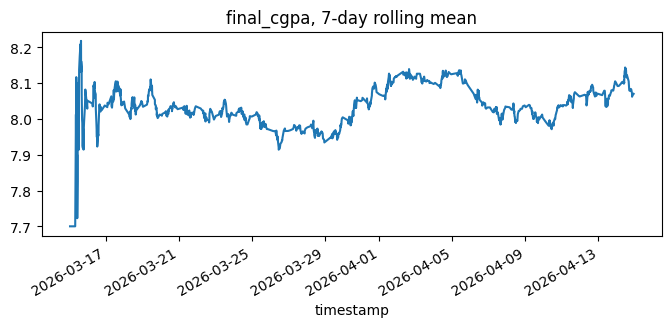

In [29]:
print("already sorted?", df["timestamp"].is_monotonic_increasing)

df = df.sort_values("timestamp").reset_index(drop=True)   # sort once
feats = build(df)

roll = pd.Series(feats["final_cgpa"].values, index=df["timestamp"]).rolling("7D").mean()
roll.plot(figsize=(8, 3), title="final_cgpa, 7-day rolling mean")
plt.show()

The file is not sorted, so I sorted it. The rolling mean goes up and down around 8.0 with no clear trend, so there is no real drift.

**Risks found:**
- File not in time order: a random split mixes past and future, so I use a chronological split.
- `performance_risk_level` comes from the target: leakage, removed.
- Students can submit twice (duplicates): same row in train and test gives a too good test score.
- 2-5% missing values: the median must be learned on the training set only.
- `cohort_code` has rare categories (12 with less than 10 students): easy to overfit.

# Part B - Data leakage
Features: the 11 numeric features + `submission_day`. I remove `student_id`, `performance_risk_level` and keep `cohort_code` out for now.

In [30]:
NUM11 = ["study_hours", "sleep_hours", "attendance_rate", "study_consistency", "tasks_on_time",
         "assignments_on_time", "revision_frequency", "career_goal_clarity",
         "daily_productivity", "stress_level", "age"]
FEATS = NUM11 + ["submission_day"]

data = feats.copy()
X = data[FEATS]
y = data["final_cgpa"]

# chronological split: first 80% train, last 20% test
n_train = int(0.8 * len(data))
X_train, X_test = X.iloc[:n_train], X.iloc[n_train:]
y_train, y_test = y.iloc[:n_train], y.iloc[n_train:]

dummy = DummyRegressor().fit(X_train, y_train)
base_test = rmse(y_test, dummy.predict(X_test))
print("baseline RMSE  train: %.3f  test: %.3f" % (rmse(y_train, dummy.predict(X_train)), base_test))

def tree(**kw):
    return make_pipeline(SimpleImputer(strategy="median"), DecisionTreeRegressor(random_state=42, **kw))

results = []

baseline RMSE  train: 1.269  test: 1.236


### B.1 Random split vs chronological split

In [31]:
Xr_train, Xr_test, yr_train, yr_test = train_test_split(X, y, test_size=0.2, random_state=42)
m = tree().fit(Xr_train, yr_train)
results.append(["Random split", rmse(yr_train, m.predict(Xr_train)), rmse(yr_test, m.predict(Xr_test))])

m = tree().fit(X_train, y_train)
results.append(["Chronological split", rmse(y_train, m.predict(X_train)), rmse(y_test, m.predict(X_test))])

pd.DataFrame(results, columns=["strategy", "train RMSE", "test RMSE"]).round(3)

,strategy,train RMSE,test RMSE
0,Random split,0.0,1.579
1,Chronological split,0.0,1.975


The tree memorizes the training set (train RMSE = 0) in both cases, and the test RMSE (1.62 and 2.02) is worse than the baseline (about 1.3 and 1.24).
The random split looks better because test students are mixed in time with the training ones (`submission_day` works almost like an id).
With the chronological split all the test rows are after the training period, like in real life, so it is the more honest result.

### B.2 Duplicate leakage

In [32]:
# 15% of the students submit the form a second time (same answers, new random timestamp)
dups = df.sample(frac=0.15, random_state=42).copy()
rng = np.random.RandomState(42)
span = (df["timestamp"].max() - df["timestamp"].min()).total_seconds()
dups["timestamp"] = df["timestamp"].min() + pd.to_timedelta(rng.uniform(0, span, len(dups)), unit="s")

aug = pd.concat([df, dups]).sort_values("timestamp").reset_index(drop=True)
print("rows:", len(df), "->", len(aug))

def chrono_test(raw):
    f = build(raw)                      # recompute submission_day
    n = int(0.8 * len(f))
    m = tree().fit(f[FEATS].iloc[:n], f["final_cgpa"].iloc[:n])
    tr = rmse(f["final_cgpa"].iloc[:n], m.predict(f[FEATS].iloc[:n]))
    te = rmse(f["final_cgpa"].iloc[n:], m.predict(f[FEATS].iloc[n:]))
    twins = raw["student_id"].iloc[n:].isin(raw["student_id"].iloc[:n]).sum()
    print("test rows with the same student in train:", twins, "/", len(f) - n)
    return tr, te

# split first (duplicates still there)
tr, te = chrono_test(aug)
results.append(["Split before removing duplicates", tr, te])

# remove duplicates (all columns except timestamp) and then split
cols = [c for c in aug.columns if c != "timestamp"]
aug_clean = aug.drop_duplicates(subset=cols).reset_index(drop=True)
tr, te = chrono_test(aug_clean)
results.append(["Remove duplicates before split", tr, te])

pd.DataFrame(results, columns=["strategy", "train RMSE", "test RMSE"]).round(3)

rows: 1200 -> 1380
test rows with the same student in train: 51 / 276
test rows with the same student in train: 0 / 240


,strategy,train RMSE,test RMSE
0,Random split,0.0,1.579
1,Chronological split,0.0,1.975
2,Split before removing duplicates,0.0,1.597
3,Remove duplicates before split,0.0,1.800


A student who submits twice gives two rows with the same answers and the same CGPA. After splitting by time, one copy can be in train and the other in test.
The tree has memorized the first one, so it predicts the second one perfectly and the test score looks better than it really is (1.56 vs 1.73 after removing duplicates first).
So duplicates must be removed **before** splitting.

### B.3 Preprocessing leakage (KNN)

In [33]:
# leaky: imputer and scaler fitted on all the data before the split
X_all = StandardScaler().fit_transform(SimpleImputer(strategy="median").fit_transform(X))
knn = KNeighborsRegressor(n_neighbors=10).fit(X_all[:n_train], y_train)
results.append(["Scaler on all data (leak)", rmse(y_train, knn.predict(X_all[:n_train])),
                rmse(y_test, knn.predict(X_all[n_train:]))])

# correct: everything in a pipeline, fitted on train only
knn_pipe = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(),
                         KNeighborsRegressor(n_neighbors=10)).fit(X_train, y_train)
results.append(["Scaler on train only (pipeline)", rmse(y_train, knn_pipe.predict(X_train)),
                rmse(y_test, knn_pipe.predict(X_test))])

pd.DataFrame(results, columns=["strategy", "train RMSE", "test RMSE"]).round(3)

,strategy,train RMSE,test RMSE
0,Random split,0.000,1.579
1,Chronological split,0.000,1.975
2,Split before removing duplicates,0.000,1.597
3,Remove duplicates before split,0.000,1.800
4,Scaler on all data (leak),1.069,1.157
5,Scaler on train only (pipeline),1.066,1.147


The two results are almost the same (1.157 vs 1.147), because with 1200 rows the mean and std of all the data are very close to those of the training set.
But the rule is still important: the test set must be "unseen", so the scaler and the median imputer must be learned on the training data only.
With a smaller dataset, outliers or drift the leak could be bigger. A Pipeline does this automatically.

# Part C - Overfitting

### C.1 Tree depth

max_depth  train RMSE  test RMSE    gap
        1       1.179      1.159 -0.020
        2       1.139      1.127 -0.013
        3       1.102      1.068 -0.034
        5       1.009      1.335  0.326
       10       0.539      1.936  1.397
       20       0.000      1.975  1.975
     None       0.000      1.975  1.975


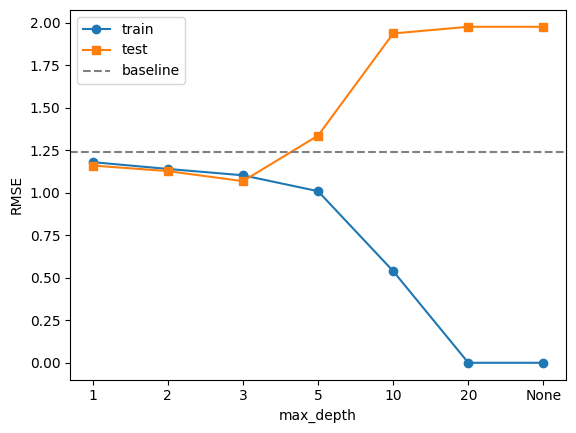

In [34]:
depths = [1, 2, 3, 5, 10, 20, None]
rows = []
for d in depths:
    m = tree(max_depth=d).fit(X_train, y_train)
    tr = rmse(y_train, m.predict(X_train))
    te = rmse(y_test, m.predict(X_test))
    rows.append([str(d), tr, te, te - tr])
depth_df = pd.DataFrame(rows, columns=["max_depth", "train RMSE", "test RMSE", "gap"])
print(depth_df.round(3).to_string(index=False))

plt.plot(depth_df["max_depth"], depth_df["train RMSE"], "o-", label="train")
plt.plot(depth_df["max_depth"], depth_df["test RMSE"], "s-", label="test")
plt.axhline(base_test, color="gray", linestyle="--", label="baseline")
plt.xlabel("max_depth"); plt.ylabel("RMSE"); plt.legend(); plt.show()

For depth 1 to 3 train and test errors are close and the best test RMSE is at depth 3 (1.07, better than the baseline 1.24).
From **depth 5** the train error keeps decreasing (1.01, 0.54, 0) but the test error increases (1.34, 1.92, 2.02) and the gap jumps from -0.03 to +0.33.
So the model starts to overfit at depth 5: it learns the noise of the training set.

### C.2 Polynomial degree of `effort_index`

 degree  CV RMSE
      1   1.1774
      2   1.1776
      3   1.1789
      5   1.1854
      9   1.1883
     15   1.2941


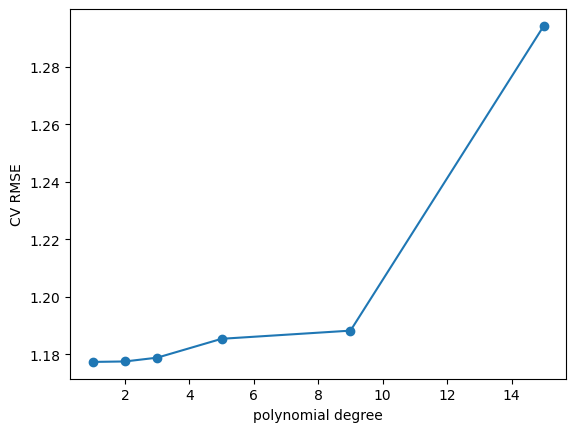

In [35]:
tscv = TimeSeriesSplit(n_splits=5)

def cv(model, Xd, yd):
    s = cross_val_score(model, Xd, yd, cv=tscv, scoring="neg_root_mean_squared_error")
    return -s.mean()

Xe_train = data[["effort_index"]].iloc[:n_train]
degrees = [1, 2, 3, 5, 9, 15]
cv_deg = []
for deg in degrees:
    pipe = make_pipeline(PolynomialFeatures(deg, include_bias=False), StandardScaler(), LinearRegression())
    cv_deg.append(cv(pipe, Xe_train, y_train))
print(pd.DataFrame({"degree": degrees, "CV RMSE": cv_deg}).round(4).to_string(index=False))

plt.plot(degrees, cv_deg, "o-")
plt.xlabel("polynomial degree"); plt.ylabel("CV RMSE"); plt.show()

The CV RMSE only goes from 1.177 (degree 1) to 1.188 (degree 15), so the effect is very small compared with C.1 (test RMSE from 1.07 to 2.02).
There is only one input variable, so the polynomial is a smooth curve that cannot isolate single students, while a deep tree with 12 features can make almost one leaf per row.
Also the relation is weak and almost linear, so degree 1 is enough.

# Part D - Improving generalization
Validation RMSE = TimeSeriesSplit (5 folds) on the training set only.

### D.1 `cohort_code`

In [36]:
XC_train = data[FEATS + ["cohort_code"]].iloc[:n_train]

def tree_cohort(encoder):
    pre = ColumnTransformer([("num", SimpleImputer(strategy="median"), FEATS),
                             ("cat", encoder, ["cohort_code"])])
    return make_pipeline(pre, DecisionTreeRegressor(max_depth=5, random_state=42))

print("rare grouping :", round(cv(tree_cohort(OneHotEncoder(min_frequency=10, handle_unknown="infrequent_if_exist",
                                                           sparse_output=False)), XC_train, y_train), 4))
print("target encoding:", round(cv(tree_cohort(TargetEncoder(cv=5, shuffle=False)), XC_train, y_train), 4))
print("removed       :", round(cv(tree(max_depth=5), X_train, y_train), 4))

rare grouping : 1.2368
target encoding: 1.3004
removed       : 1.2549


Rare grouping 1.237, removal 1.255, target encoding 1.300. Target encoding is the worst (the target mean of small categories is very noisy).
Rare grouping is slightly better than removal but the difference (0.02) is much smaller than the variation between folds (about 0.1), so it is not significant.
`cohort_code` has almost no information about the CGPA. **I remove it** (simpler model).

### D.2 Keep `submission_day`?

In [37]:
def model(name):
    if name == "Linear Regression":
        m = LinearRegression()
    elif name == "Decision Tree":
        m = DecisionTreeRegressor(max_depth=5, random_state=42)
    else:
        m = GradientBoostingRegressor(n_estimators=60, learning_rate=0.05, max_depth=3, random_state=42)
    return make_pipeline(SimpleImputer(strategy="median"), m)

rows = []
for name in ["Linear Regression", "Decision Tree", "Gradient Boosting"]:
    rows.append([name, cv(model(name), X_train[FEATS], y_train), cv(model(name), X_train[NUM11], y_train)])
print(pd.DataFrame(rows, columns=["model", "with submission_day", "without"]).round(4).to_string(index=False))

            model  with submission_day  without
Linear Regression               1.1258   1.1182
    Decision Tree               1.2549   1.2015
Gradient Boosting               1.1414   1.1275


Without `submission_day` the validation RMSE is lower for the three models. This is logical: the feature has no relation with the CGPA (r = 0.02, no drift)
and in a chronological split the test values are outside the training range, so it only helps to memorize rows. **I remove it.**

### D.3 Regularization (degree 5 polynomial of `effort_index`)

In [38]:
alphas = [0.001, 0.01, 0.1, 1, 10, 100]

def poly5(m):
    return make_pipeline(PolynomialFeatures(5, include_bias=False), StandardScaler(), m)

print("Linear Regression CV RMSE:", round(cv(poly5(LinearRegression()), Xe_train, y_train), 4))
ridge_cv = [cv(poly5(Ridge(alpha=a)), Xe_train, y_train) for a in alphas]
lasso_cv = [cv(poly5(Lasso(alpha=a, max_iter=100000)), Xe_train, y_train) for a in alphas]
print(pd.DataFrame({"alpha": alphas, "Ridge": ridge_cv, "Lasso": lasso_cv}).round(4).to_string(index=False))

best_ridge = alphas[int(np.argmin(ridge_cv))]
best_lasso = alphas[int(np.argmin(lasso_cv))]
print("best alpha: Ridge =", best_ridge, ", Lasso =", best_lasso)

coefs = pd.DataFrame(index=["x1", "x2", "x3", "x4", "x5"])
for name, m in [("Linear", LinearRegression()), ("Ridge", Ridge(alpha=best_ridge)),
                ("Lasso", Lasso(alpha=best_lasso, max_iter=100000))]:
    coefs[name] = poly5(m).fit(Xe_train, y_train)[-1].coef_
print(coefs.round(3))
print("Lasso coefficients equal to zero:", (coefs["Lasso"] == 0).sum(), "out of 5")

Linear Regression CV RMSE: 1.1854
  alpha  Ridge  Lasso
  0.001 1.1808 1.1781
  0.010 1.1800 1.1771
  0.100 1.1790 1.1772
  1.000 1.1784 1.2680
 10.000 1.1782 1.2680
100.000 1.1805 1.2680
best alpha: Ridge = 10 , Lasso = 0.01
    Linear  Ridge  Lasso
x1   8.831  0.394  0.471
x2 -37.753  0.156  0.000
x3  66.183  0.015  0.000
x4 -52.515 -0.049 -0.000
x5  15.761 -0.049 -0.000
Lasso coefficients equal to zero: 4 out of 5


Linear regression has CV RMSE 1.185, Ridge 1.178 (alpha = 10) and Lasso 1.177 (alpha = 0.01).
The biggest change is in the coefficients: linear regression has huge coefficients (up to about 66, they cancel each other), Ridge makes all of them small (below 0.5),
and Lasso sets **4 out of 5 to exactly zero** and keeps only the linear term. So the real relation is almost linear.

### D.4 Final comparison on the test set

Features: the 11 features of Part B, without `submission_day` (D.2) and without `cohort_code` (D.1).

best Ridge/Lasso: (np.float64(1.1072913789794698), 'Lasso', 0.1)
best max_depth: 3
best number of trees: 48


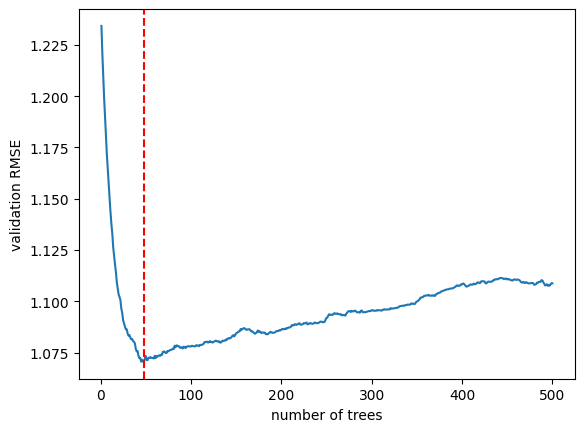

,Model,Training RMSE,Testing RMSE,Testing R2,Gap
0,Baseline (training mean),1.2685,1.2362,-0.0029,-0.0324
1,Linear Regression,1.0897,1.0576,0.2659,-0.0321
2,"Ridge / Lasso (Lasso, alpha=0.1)",1.1064,1.0721,0.2457,-0.0343
3,Decision Tree (depth=3),1.1021,1.0677,0.2519,-0.0344
4,Gradient Boosting (48 trees),1.0454,1.0573,0.2664,0.0119


In [39]:
Xf_train, Xf_test = data[NUM11].iloc[:n_train], data[NUM11].iloc[n_train:]

def lin(m):
    return make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), m)

# Ridge / Lasso: choose alpha with TimeSeriesSplit
best = None
for name, Model in [("Ridge", Ridge), ("Lasso", Lasso)]:
    for a in alphas:
        score = cv(lin(Model(alpha=a, max_iter=100000) if name == "Lasso" else Model(alpha=a)), Xf_train, y_train)
        if best is None or score < best[0]:
            best = (score, name, a)
print("best Ridge/Lasso:", best)
reg = lin(Ridge(alpha=best[2]) if best[1] == "Ridge" else Lasso(alpha=best[2], max_iter=100000))

# Decision tree: choose max_depth with TimeSeriesSplit
tree_cv = [cv(tree(max_depth=d), Xf_train, y_train) for d in depths]
best_depth = depths[int(np.argmin(tree_cv))]
print("best max_depth:", best_depth)

# Gradient boosting with early stopping: last 15% of train = validation block
n_val = int(0.15 * len(Xf_train))
Xa, Xv = Xf_train.iloc[:-n_val], Xf_train.iloc[-n_val:]
ya, yv = y_train.iloc[:-n_val], y_train.iloc[-n_val:]
imp = SimpleImputer(strategy="median").fit(Xa)
gb = GradientBoostingRegressor(n_estimators=500, learning_rate=0.05, max_depth=3, random_state=42)
gb.fit(imp.transform(Xa), ya)
val_rmse = [rmse(yv, p) for p in gb.staged_predict(imp.transform(Xv))]
best_n = int(np.argmin(val_rmse)) + 1
print("best number of trees:", best_n)

plt.plot(range(1, 501), val_rmse)
plt.axvline(best_n, color="red", linestyle="--")
plt.xlabel("number of trees"); plt.ylabel("validation RMSE"); plt.show()

# refit everything on the full training set and test (first and only time we use the test set)
models = {
    "Baseline (training mean)": DummyRegressor(),
    "Linear Regression": lin(LinearRegression()),
    "Ridge / Lasso (%s, alpha=%s)" % (best[1], best[2]): reg,
    "Decision Tree (depth=%s)" % best_depth: tree(max_depth=best_depth),
    "Gradient Boosting (%d trees)" % best_n: make_pipeline(
        SimpleImputer(strategy="median"),
        GradientBoostingRegressor(n_estimators=best_n, learning_rate=0.05, max_depth=3, random_state=42)),
}
rows = []
for name, m in models.items():
    m.fit(Xf_train, y_train)
    rows.append([name, rmse(y_train, m.predict(Xf_train)), rmse(y_test, m.predict(Xf_test)),
                 r2_score(y_test, m.predict(Xf_test))])
final = pd.DataFrame(rows, columns=["Model", "Training RMSE", "Testing RMSE", "Testing R2"])
final["Gap"] = final["Testing RMSE"] - final["Training RMSE"]
final.round(4)

# Final discussion

**1. Best generalization:** Linear Regression and Gradient Boosting are tied (test RMSE about 1.057, R² = 0.27, baseline 1.236). The tree (depth 3, 1.068) and Lasso (1.072) are very close.
The differences are too small to be significant on 240 test rows, so the simplest one (Linear Regression) is a safe choice.

**2. Largest generalization gap:** Gradient Boosting among the final models (+0.012), because it is the most flexible. The others have a small negative gap because the test period is slightly easier than the training period.
The biggest gap of the whole session is the full tree in C.1 (train RMSE 0, test 2.02, gap +2.0).

**3. Most effective techniques:** Limiting the tree depth (test RMSE from 2.02 to about 1.07), removing useless features (`submission_day`, `cohort_code`), regularization (polynomial coefficients from about 181 in total to less than 1) and early stopping for boosting (only 48 trees).
Splitting correctly (no duplicates, chronological, pipeline) does not reduce overfitting but measures it honestly.

**4. Why validation and not training performance:** Training error always prefers more complex models (a full tree has train RMSE 0 but test RMSE 2.02). Only data not used for fitting shows how the model works on new students.

**5. Why keep the test set untouched:** If we use it to choose the model or hyperparameters, it becomes part of the tuning and the score is too optimistic. We would have no honest estimate of the final performance.

**6. Why is R² modest:** The best R² is only 0.27 and the best correlation is 0.38. The survey is self-reported, the answers are ranges and the target is a self-declared band with 4 values, so most of the variance of the CGPA is not in these features (or is noise).
A high score is not always good: it can come from leakage (e.g. `performance_risk_level`, duplicates in train and test, a scaler fitted on all the data, a random split of time-ordered data) or from tuning on the test set.
In B.2 the duplicates gave a better score (1.56 vs 1.73) without any real improvement.